# Baseline Model — Academic Early-Warning System


In [3]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

## Pre-requirements
- `DATA_PATH`: .csv with file path
- `TARGET_COLUMN`:Specific column objective. must be 0 or 1.
- `NUMERIC_FEATURES`:Numrical features available about T1.
- `CATEGORICAL_FEATURES`:Categorical features available about T1.
- `ID_COLUMN`: Optional, not included into the model.
- `TIME_COLUMN`: Optional, if exist will be used for timaline split.
- `LEAKAGE_COLUMNS`: Which future columns or discovering the objective.

In [4]:
DATA_PATH = Path("notebooks/Cleaned_synthetic_stu_Data.csv")

TARGET_COLUMN = "Academic risk"
TIME_COLUMN = "Academic Term"
ID_COLUMN = "anonymous_student_identifier"


NUMERIC_FEATURES = [
    "attendance_week_1_4",
    "early_assessment_result",
]

CATEGORICAL_FEATURES = [
    "program",
    "academic_term",
]


LEAKAGE_COLUMNS = [
    "Course Outcomes",
    "Semester GPA",
    "Cumulative GPA",
    "Progression Status",
    "Credits Completed",
    
]

POSITIVE_LABEL = 1
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15
DEFAULT_THRESHOLD = 0.50
TARGET_RECALL = 0.80 
# Precision , Recall 


OUTPUT_DIR = Path("model/Baseline_model")
MODEL_DIR = Path("model/trained")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
# ================================================================

## Load the data and valiedate from sittings

In [5]:
def validate_configuration():
    errors = []
    if not str(DATA_PATH):
        errors.append("DATA_PATH")
    elif not DATA_PATH.exists():
        errors.append(f"File not found!{DATA_PATH.resolve()}")
    if not TARGET_COLUMN:
        errors.append("TARGET_COLUMN")
    if not NUMERIC_FEATURES and not CATEGORICAL_FEATURES:
        errors.append("You need to choose one of features at least")
    duplicated = set(NUMERIC_FEATURES) & set(CATEGORICAL_FEATURES)
    if duplicated:
        errors.append(f"`duplicated columns between numrical & categorical` {sorted(duplicated)}")
    if errors:
        raise ValueError("\n- " + "\n- ".join(errors))

if not DATA_PATH.exists():
    for folder in (Path.cwd(), *Path.cwd().parents):
        candidate = folder / DATA_PATH.name
        if candidate.is_file():
            DATA_PATH = candidate
            break

validate_configuration()
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Dataset shape: 212 rows × 17 columns


,anonymous_student_identifier,program,academic_term,course_attempts,credits_attempted,credits_completed,course_outcomes,semester_gpa,cumulative_gpa,withdrawals,repeated_courses,progression_status,attendance,early_assessment_results,academic_risk,has_repeated_courses,has_withdrawals
0,STU_0001,Psychology,2025-Fall,5,15,15,"CRSE-121: 2.0, CRSE-352: 2.4, CRSE-335: 1.6, C...",1.85,1.85,0,0,Academic Warning,NaN,Fail,1,0,0
1,STU_0002,Psychology,2025-Fall,4,12,12,"CRSE-428: 2.0, CRSE-266: 2.4, CRSE-373: 2.6, C...",2.43,2.43,0,0,Good Standing,NaN,NaN,0,0,0
2,STU_0002,Psychology,2026-Spring,4,12,12,"CRSE-134: 2.2, CRSE-305: 1.4, CRSE-180: 2.7, C...",2.00,2.22,0,0,Good Standing,NaN,NaN,0,0,0
3,STU_0002,Psychology,2026-Fall,4,12,12,"CRSE-370: 2.4, CRSE-314: 1.8, CRSE-351: 2.4, C...",2.41,2.28,0,0,Good Standing,95%,NaN,0,0,0
4,STU_0003,Nursing,2025-Fall,5,15,15,"CRSE-360: 1.6, CRSE-330: 2.3, CRSE-140: 2.5, C...",2.34,2.34,0,0,Good Standing,NaN,NaN,0,0,0


## Lookups for columns and objectives and Data Leakage

In [6]:
selected_features = NUMERIC_FEATURES + CATEGORICAL_FEATURES
required_columns = selected_features + [TARGET_COLUMN]
if TIME_COLUMN:
    required_columns.append(TIME_COLUMN)

missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    # Normalize dataset column names to the names used by the notebook
    if TARGET_COLUMN not in df.columns and "academic_risk" in df.columns:
        TARGET_COLUMN = "academic_risk"
    if TIME_COLUMN not in df.columns and "academic_term" in df.columns:
        TIME_COLUMN = "academic_term"

    for expected, actual in {
        "attendance_week_1_4": "attendance",
        "early_assessment_result": "early_assessment_results",
    }.items():
        if expected not in df.columns and actual in df.columns:
            df = df.rename(columns={actual: expected})

    selected_features = NUMERIC_FEATURES + CATEGORICAL_FEATURES
    required_columns = selected_features + [TARGET_COLUMN]
    if TIME_COLUMN:
        required_columns.append(TIME_COLUMN)

    missing_columns = sorted(set(required_columns) - set(df.columns))
    if missing_columns:
        raise KeyError(
            f"Columns not present in the dataset. "
            f"Expected: {required_columns}. "
            f"Available: {list(df.columns)}"
        )

leakage_selected = sorted(set(selected_features) & set(LEAKAGE_COLUMNS))
if leakage_selected:
    raise ValueError(f"Data Leakage columns:  {leakage_selected}")

if TARGET_COLUMN in selected_features:
    raise ValueError("You cannot put TARGET_COLUMN into features ")
if ID_COLUMN and ID_COLUMN in selected_features:
    raise ValueError("ID_column cannot be feature")

model_df = df.dropna(subset=[TARGET_COLUMN]).copy()
model_df[TARGET_COLUMN] = pd.to_numeric(model_df[TARGET_COLUMN], errors="raise").astype(int)

unexpected_labels = sorted(set(model_df[TARGET_COLUMN].unique()) - {0, 1})
if unexpected_labels:
    raise ValueError(f"an expected values cannot be 0 or 1{unexpected_labels}")
if model_df[TARGET_COLUMN].nunique() != 2:
    raise ValueError("The objective contains only one،You cannot train binary categorical model")
                                              
feature_audit = pd.DataFrame({
    "feature": selected_features,
    "type": ["numeric" if c in NUMERIC_FEATURES else "categorical" for c in selected_features],
    "missing_count": [model_df[c].isna().sum() for c in selected_features],
    "missing_pct": [round(model_df[c].isna().mean() * 100, 2) for c in selected_features],
    "unique_values": [model_df[c].nunique(dropna=True) for c in selected_features],
})
display(feature_audit)

class_distribution = model_df[TARGET_COLUMN].value_counts().sort_index().rename("count").to_frame()
class_distribution["percentage"] = (
    model_df[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100
).round(2)
display(class_distribution)

,feature,type,missing_count,missing_pct,unique_values
0,attendance_week_1_4,numeric,110,51.89,27
1,early_assessment_result,numeric,130,61.32,3
2,program,categorical,0,0.00,5
3,academic_term,categorical,0,0.00,3


,count,percentage
academic_risk,,
0,182,85.85
1,30,14.15


## Split the data


In [7]:
X = model_df[selected_features].copy()
y = model_df[TARGET_COLUMN].copy()

def chronological_split(X, y, time_values, test_size=0.15, validation_size=0.15):
    order = pd.Series(time_values, index=X.index).sort_values(kind="stable").index
    Xs, ys = X.loc[order], y.loc[order]
    n = len(Xs)
    train_end = int(n * (1 - test_size - validation_size))
    valid_end = int(n * (1 - test_size))
    return (
        Xs.iloc[:train_end], Xs.iloc[train_end:valid_end], Xs.iloc[valid_end:],
        ys.iloc[:train_end], ys.iloc[train_end:valid_end], ys.iloc[valid_end:]
    )

if TIME_COLUMN:
    time_values = model_df.loc[X.index, TIME_COLUMN]
    X_train, X_valid, X_test, y_train, y_valid, y_test = chronological_split(
        X, y, time_values, TEST_SIZE, VALIDATION_SIZE
    )
    split_method = "chronological"
else:
    temp_size = TEST_SIZE + VALIDATION_SIZE
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=temp_size, stratify=y,
        random_state=RANDOM_STATE
    )
    relative_test_size = TEST_SIZE / temp_size
    X_valid, X_test, y_valid, y_test = train_test_split(
        X_temp, y_temp, test_size=relative_test_size,
        stratify=y_temp, random_state=RANDOM_STATE
    )
    split_method = "stratified_random"

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "positive_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
})
print("Split method:", split_method)
display(split_summary)

for name, target in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    if target.nunique() < 2:
        raise ValueError(f"{name}Contains only onecategory, use more data or review the split.")
                      

Split method: chronological


,split,rows,positive_rate
0,Train,148,0.162162
1,Validation,32,0.062500
2,Test,32,0.125000


##  Build Pipeline basic model

- StandardScaler.
- One-Hot Encoding.
- Model: Logistic Regression with`class_weight="balanced"`.

In [8]:
from sklearn.preprocessing import FunctionTransformer

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

def clean_numeric_features(values):
    values = values.copy()
    values["attendance_week_1_4"] = pd.to_numeric(
        values["attendance_week_1_4"]
        .astype("string")
        .str.rstrip("%"),
        errors="coerce",
    )
    values["early_assessment_result"] = (
        values["early_assessment_result"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({"fail": 0, "marginal": 1, "pass": 2})
    )
    return values

numeric_pipeline = Pipeline(steps=[
    ("clean", FunctionTransformer(clean_numeric_features, validate=False)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

baseline_pipeline.fit(X_train, y_train)
print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


## Assesmenr united finction

In [9]:
def evaluate_binary_classifier(y_true, y_probability, threshold=0.50):
    y_pred = (np.asarray(y_probability) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall_sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_probability),
        "pr_auc_average_precision": average_precision_score(y_true, y_probability),
        "brier_score": brier_score_loss(y_true, y_probability),
        "false_positive_rate": fpr,
        "false_negative_rate": fnr,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

## Performance Validation on Threshold = 0.50

In [10]:
valid_probability = baseline_pipeline.predict_proba(X_valid)[:, 1]
valid_default_metrics = pd.DataFrame([
    evaluate_binary_classifier(y_valid, valid_probability, DEFAULT_THRESHOLD)
])
display(valid_default_metrics.T.rename(columns={0: "value"}))

,value
threshold,0.500000
accuracy,0.937500
balanced_accuracy,0.500000
precision,0.000000
recall_sensitivity,0.000000
specificity,1.000000
f1,0.000000
roc_auc,0.966667
pr_auc_average_precision,0.750000
brier_score,0.052279


##  Select Threshold using Validation only


In [11]:
threshold_rows = []
for threshold in np.round(np.arange(0.05, 0.96, 0.01), 2):
    threshold_rows.append(
        evaluate_binary_classifier(y_valid, valid_probability, float(threshold))
    )
threshold_table = pd.DataFrame(threshold_rows)

eligible = threshold_table[threshold_table["recall_sensitivity"] >= TARGET_RECALL]
if not eligible.empty:
    best_row = eligible.sort_values(
        ["precision", "f1", "threshold"], ascending=[False, False, False]
    ).iloc[0]
    selection_rule = f"Highest precision with recall >= {TARGET_RECALL:.0%}"
else:
    best_row = threshold_table.sort_values(
        ["f1", "recall_sensitivity"], ascending=[False, False]
    ).iloc[0]
    selection_rule = "Highest F1 because target recall was not reached"

SELECTED_THRESHOLD = float(best_row["threshold"])
print("Selection rule:", selection_rule)
print(f"Selected threshold: {SELECTED_THRESHOLD:.2f}")
display(threshold_table.sort_values("f1", ascending=False).head(10))

Selection rule: Highest precision with recall >= 80%
Selected threshold: 0.23


,threshold,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc_average_precision,brier_score,false_positive_rate,false_negative_rate,tn,fp,fn,tp
16,0.21,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
13,0.18,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
14,0.19,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
15,0.20,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
17,0.22,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
18,0.23,0.93750,0.966667,0.5,1.0,0.933333,0.666667,0.966667,0.75,0.052279,0.066667,0.0,28,2,0,2
33,0.38,0.96875,0.750000,1.0,0.5,1.000000,0.666667,0.966667,0.75,0.052279,0.000000,0.5,30,0,1,1
31,0.36,0.96875,0.750000,1.0,0.5,1.000000,0.666667,0.966667,0.75,0.052279,0.000000,0.5,30,0,1,1
30,0.35,0.96875,0.750000,1.0,0.5,1.000000,0.666667,0.966667,0.75,0.052279,0.000000,0.5,30,0,1,1
29,0.34,0.96875,0.750000,1.0,0.5,1.000000,0.666667,0.966667,0.75,0.052279,0.000000,0.5,30,0,1,1


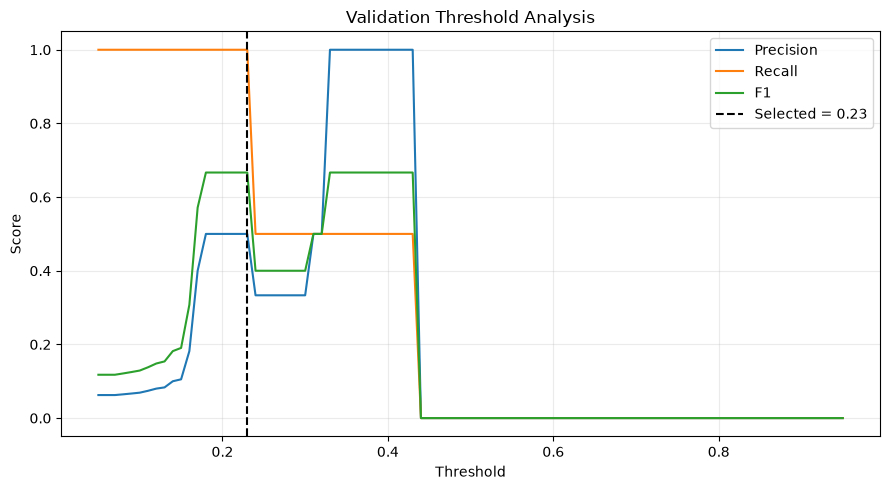

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall_sensitivity"], label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
plt.axvline(SELECTED_THRESHOLD, color="black", linestyle="--", label=f"Selected = {SELECTED_THRESHOLD:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Analysis")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Final Test on threshold.

In [13]:
test_probability = baseline_pipeline.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= SELECTED_THRESHOLD).astype(int)

test_metrics = pd.DataFrame([
    evaluate_binary_classifier(y_test, test_probability, SELECTED_THRESHOLD)
])
display(test_metrics.T.rename(columns={0: "value"}))

print("Classification Report")
print(classification_report(y_test, test_prediction, digits=4, zero_division=0))

,value
threshold,0.230000
accuracy,0.625000
balanced_accuracy,0.464286
precision,0.100000
recall_sensitivity,0.250000
specificity,0.678571
f1,0.142857
roc_auc,0.642857
pr_auc_average_precision,0.387228
brier_score,0.129531


Classification Report
              precision    recall  f1-score   support

           0     0.8636    0.6786    0.7600        28
           1     0.1000    0.2500    0.1429         4

    accuracy                         0.6250        32
   macro avg     0.4818    0.4643    0.4514        32
weighted avg     0.7682    0.6250    0.6829        32



## 10. Confusion Matrix

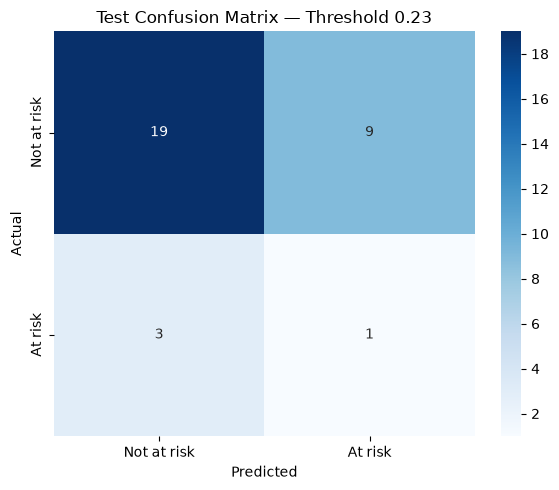

In [14]:
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not at risk", "At risk"],
            yticklabels=["Not at risk", "At risk"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Test Confusion Matrix — Threshold {SELECTED_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()

## ROC Precision-Recall

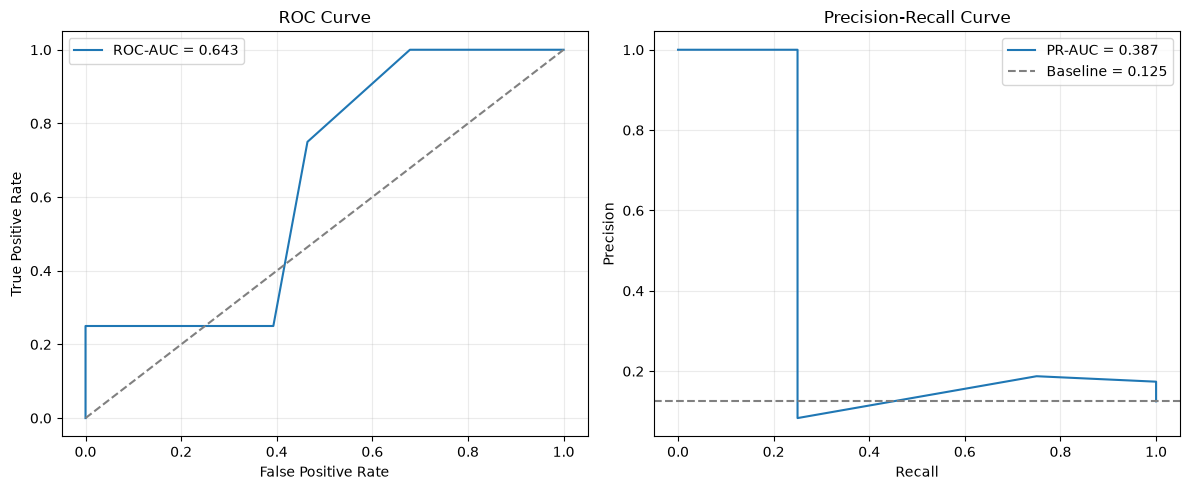

In [15]:
fpr, tpr, _ = roc_curve(y_test, test_probability)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probability)
roc_auc = roc_auc_score(y_test, test_probability)
pr_auc = average_precision_score(y_test, test_probability)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label=f"Baseline = {y_test.mean():.3f}")
axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Calibration

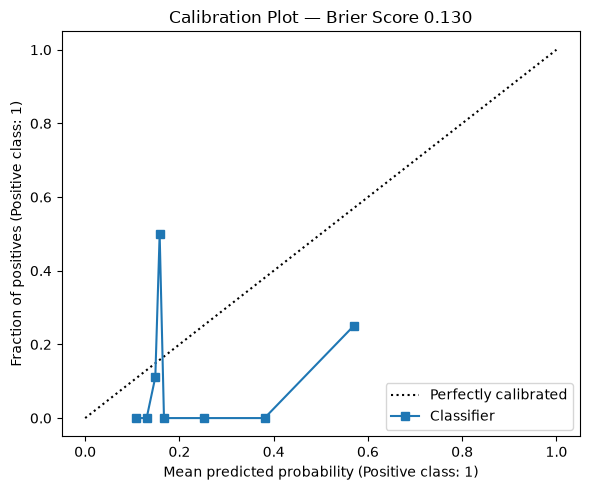

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(
    y_test, test_probability, n_bins=10, strategy="quantile", ax=ax
)
ax.set_title(f"Calibration Plot — Brier Score {brier_score_loss(y_test, test_probability):.3f}")
plt.tight_layout()
plt.show()

# Explainity the transactions Logistic Regression

In [17]:
preprocessor = baseline_pipeline.named_steps["preprocessor"]
categorical_encoder = (
    preprocessor.named_transformers_["categorical"].named_steps["onehot"]
)

feature_names = list(NUMERIC_FEATURES) + list(
    categorical_encoder.get_feature_names_out(CATEGORICAL_FEATURES)
)
coefficients = baseline_pipeline.named_steps["model"].coef_[0]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients),
    "absolute_coefficient": np.abs(coefficients),
}).sort_values("absolute_coefficient", ascending=False)

display(coefficient_table.head(20))

,feature,coefficient,odds_ratio,absolute_coefficient
7,academic_term_2025-Fall,1.143219,3.136849,1.143219
9,academic_term_2026-Spring,-0.667875,0.512797,0.667875
8,academic_term_2026-Fall,-0.475254,0.621727,0.475254
1,early_assessment_result,-0.417378,0.658772,0.417378
0,attendance_week_1_4,-0.347363,0.706549,0.347363
6,program_Psychology,-0.240943,0.785886,0.240943
5,program_Nursing,0.155995,1.168820,0.155995
4,program_Mechanical Engineering,0.093814,1.098356,0.093814
3,program_Computer Science,-0.052622,0.948739,0.052622
2,program_Business Administration,0.043846,1.044822,0.043846


## Saving Model and Results.

In [18]:
model_path = MODEL_DIR / "baseline_logistic_regression.joblib"
metrics_path = OUTPUT_DIR / "test_metrics.csv"
threshold_path = OUTPUT_DIR / "threshold_analysis.csv"
coefficients_path = OUTPUT_DIR / "model_coefficients.csv"
predictions_path = OUTPUT_DIR / "test_predictions.csv"
metadata_path = OUTPUT_DIR / "baseline_metadata.json"

joblib.dump(baseline_pipeline, model_path)
test_metrics.to_csv(metrics_path, index=False)
threshold_table.to_csv(threshold_path, index=False)
coefficient_table.to_csv(coefficients_path, index=False)

prediction_output = pd.DataFrame({
    "actual": y_test,
    "risk_probability": test_probability,
    "predicted_class": test_prediction,
}, index=X_test.index)
if ID_COLUMN and ID_COLUMN in model_df.columns:
    prediction_output.insert(0, ID_COLUMN, model_df.loc[X_test.index, ID_COLUMN])
prediction_output.to_csv(predictions_path, index=False)

metadata = {
    "model": "LogisticRegression",
    "dataset": str(DATA_PATH),
    "target": TARGET_COLUMN,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "blocked_leakage_columns": LEAKAGE_COLUMNS,
    "split_method": split_method,
    "selected_threshold": SELECTED_THRESHOLD,
    "threshold_selection_rule": selection_rule,
    "target_recall": TARGET_RECALL,
    "random_state": RANDOM_STATE,
    "train_rows": len(X_train),
    "validation_rows": len(X_valid),
    "test_rows": len(X_test),
}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

print("Saved outputs:")
for path in [model_path, metrics_path, threshold_path, coefficients_path, predictions_path, metadata_path]:
    print("-", path)

Saved outputs:
- model\trained\baseline_logistic_regression.joblib
- model\Baseline_model\test_metrics.csv
- model\Baseline_model\threshold_analysis.csv
- model\Baseline_model\model_coefficients.csv
- model\Baseline_model\test_predictions.csv
- model\Baseline_model\baseline_metadata.json


# predecting and apply the model


In [19]:

# loaded_model = joblib.load(MODEL_DIR / "baseline_logistic_regression.joblib")
# new_students = pd.read_csv("new_students_at_t1.csv")
# risk_probability = loaded_model.predict_proba(new_students[selected_features])[:, 1]
# risk_flag = (risk_probability >= SELECTED_THRESHOLD).astype(int)
# results = pd.DataFrame({
#     "risk_probability": risk_probability,
#     "risk_flag": risk_flag,
# })
# display(results.head())

## Summary report

**Baseline model:** Logistic Regression was trained using only features available at prediction time T1. Numerical missing values were imputed using the training-set median, categorical missing values using the most frequent training-set category, numerical features were standardized, and categorical features were one-hot encoded. The decision threshold was selected using the validation set only, while the held-out test set was reserved for final evaluation. Performance was reported using Precision, Recall, F1, ROC-AUC, PR-AUC, Balanced Accuracy, Brier Score, and the Confusion Matrix.


# Fairness Evaluation

In [20]:
fairness_df = X_test.copy()

fairness_df["actual"] = y_test.values
fairness_df["predicted"] = test_prediction

fairness_df[["program", "actual", "predicted"]].head()

,program,actual,predicted
119,Business Administration,1,0
121,Nursing,0,0
123,Business Administration,0,0
125,Psychology,0,1
127,Mechanical Engineering,1,1


In [21]:
from sklearn.metrics import precision_score, recall_score

fairness_results = []

for program in fairness_df["program"].unique():
    group = fairness_df[fairness_df["program"] == program]

    fairness_results.append({
        "Program": program,
        "Students": len(group),
        "At Risk": group["actual"].sum(),
        "Predicted At Risk": group["predicted"].sum(),
        "Precision": precision_score(
            group["actual"],
            group["predicted"],
            zero_division=0
        ),
        "Recall": recall_score(
            group["actual"],
            group["predicted"],
            zero_division=0
        )
    })

fairness_results = pd.DataFrame(fairness_results)

display(fairness_results)

,Program,Students,At Risk,Predicted At Risk,Precision,Recall
0,Business Administration,10,1,2,0.0,0.000000
1,Nursing,3,0,1,0.0,0.000000
2,Psychology,3,0,1,0.0,0.000000
3,Mechanical Engineering,12,3,5,0.2,0.333333
4,Computer Science,4,0,1,0.0,0.000000
